# 01. Exploration et Prétraitement des Données
Ce carnet réalise l'analyse exploratoire initiale (EDA) et met en place le pipeline de prétraitement robuste pour la modélisation.



In [307]:
import pandas as pd
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import seaborn as sns

In [308]:
df = pd.read_excel("../data/raw/dataset-uci.xlsx")
print(f"Nombre total de lignes dans le brut : {len(df)}")
df.head()

Nombre total de lignes dans le brut : 296


,Unnamed: 0,Case Type,Tumour Case,Age of Mother,Age of Father,Age at First Diagnosis,Café au lait (CLS),Axillary Freckles,Inguinal Freckles,Lisch Nodules,Dermal Neurofibromins,Plexiform Neurofibromins,Optic Glioma,Skeletal Dysplasia,Learning Disability,Hypertension,Astrocytoma,Hamartoma,Scoliosis,Other Symptoms
0,1,0,1,30.0,31.0,5.0,0,0,0,0,0,0,1,0,0,0,0,0,0,1
1,2,0,1,22.0,29.0,7.0,1,1,0,0,1,0,0,0,0,0,0,0,0,1
2,3,1,1,28.0,26.0,9.0,1,1,0,0,1,0,0,1,0,0,0,0,0,1
3,4,0,1,30.0,34.0,9.0,1,1,0,1,0,1,0,0,0,0,0,0,0,1
4,5,0,1,27.0,34.0,1.0,1,1,1,0,0,0,1,0,0,0,0,0,0,1


In [309]:
df.drop(columns="Unnamed: 0").duplicated().sum()

np.int64(0)

In [310]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                296 non-null    int64  
 1   Case Type                 296 non-null    int64  
 2   Tumour Case               296 non-null    int64  
 3   Age of Mother             261 non-null    float64
 4   Age of Father             262 non-null    float64
 5   Age at First Diagnosis    292 non-null    float64
 6   Café au lait (CLS)        296 non-null    int64  
 7   Axillary Freckles         296 non-null    int64  
 8   Inguinal Freckles         296 non-null    int64  
 9   Lisch Nodules             296 non-null    int64  
 10  Dermal Neurofibromins     296 non-null    int64  
 11  Plexiform Neurofibromins  296 non-null    int64  
 12  Optic Glioma              296 non-null    int64  
 13  Skeletal Dysplasia        296 non-null    int64  
 14  Learning Disability  

In [311]:
df[["Age of Mother", "Age of Father", "Age at First Diagnosis"]].describe()

,Age of Mother,Age of Father,Age at First Diagnosis
count,261.000000,262.000000,292.000000
mean,27.176245,31.881679,11.878425
std,5.801158,6.702013,10.731643
min,16.000000,19.000000,0.500000
25%,23.000000,27.000000,4.750000
50%,27.000000,31.000000,9.000000
75%,31.000000,35.000000,15.000000
max,45.000000,62.000000,61.000000


Analyse de la cible et valeurs manquantes

In [312]:
print("\n--- 1. DISTRIBUTION BRUTE (FICHIER ORIGINAL) ---")
print(df["Case Type"].value_counts())
print(f"Nombre total de lignes dans le brut : {len(df)}")
missing_target = df["Case Type"].isna().sum()
print(f"Valeurs manquantes sur la cible (Case Type) : {missing_target}")

print("\n--- 2. VALEURS MANQUANTES GLOBALES ---")
missing = df.isna().sum()
print(missing[missing > 0])


--- 1. DISTRIBUTION BRUTE (FICHIER ORIGINAL) ---
Case Type
0    161
1    135
Name: count, dtype: int64
Nombre total de lignes dans le brut : 296
Valeurs manquantes sur la cible (Case Type) : 0

--- 2. VALEURS MANQUANTES GLOBALES ---
Age of Mother             35
Age of Father             34
Age at First Diagnosis     4
dtype: int64


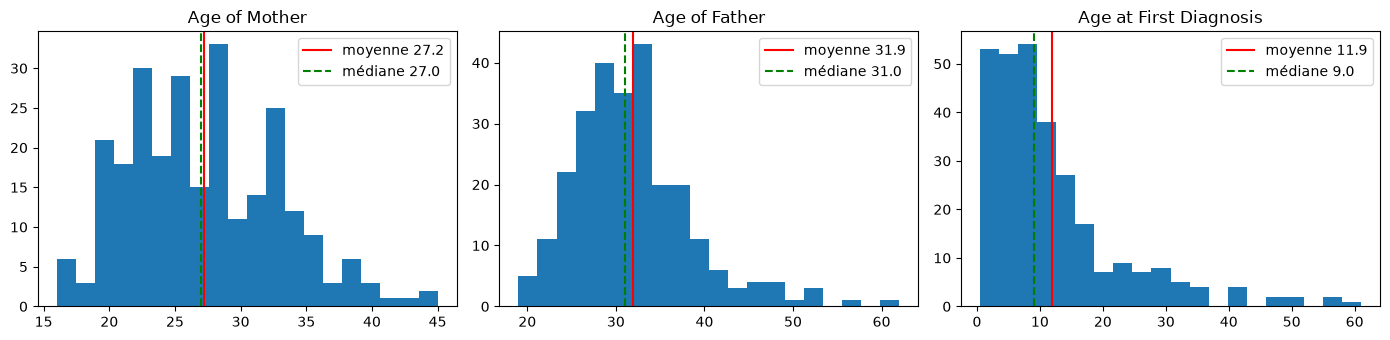

                        moyenne  médiane  asymétrie
Age of Mother             27.18     27.0       0.44
Age of Father             31.88     31.0       1.11
Age at First Diagnosis    11.88      9.0       1.90


In [313]:
cols_age = ["Age of Mother", "Age of Father", "Age at First Diagnosis"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, cols_age):
    serie = df[c].dropna()
    ax.hist(serie, bins=20)
    ax.axvline(serie.mean(), color="red", label=f"moyenne {serie.mean():.1f}")
    ax.axvline(serie.median(), color="green", linestyle="--", label=f"médiane {serie.median():.1f}")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"moyenne": df[cols_age].mean(), "médiane": df[cols_age].median(),
                    "asymétrie": df[cols_age].skew()}).round(2))

In [314]:
print("--- 1. DISTRIBUTION DE LA CIBLE (Case Type) ---")
target_dist = df["Case Type"].value_counts().sort_index()
display(target_dist.rename("effectif").to_frame())

print("\n--- 2. TAUX DE VALEURS MANQUANTES POUR LES ÂGES ---")
missing_stats = pd.DataFrame({
    "Nb_manquants": df[cols_age].isna().sum(),
    "Taux_(%)": (df[cols_age].isna().mean() * 100).round(2)
})
display(missing_stats)

--- 1. DISTRIBUTION DE LA CIBLE (Case Type) ---


,effectif
Case Type,
0,161
1,135



--- 2. TAUX DE VALEURS MANQUANTES POUR LES ÂGES ---


,Nb_manquants,Taux_(%)
Age of Mother,35,11.82
Age of Father,34,11.49
Age at First Diagnosis,4,1.35


## Quelle est l'influence de l'âge du père en fonction du type de cas ?

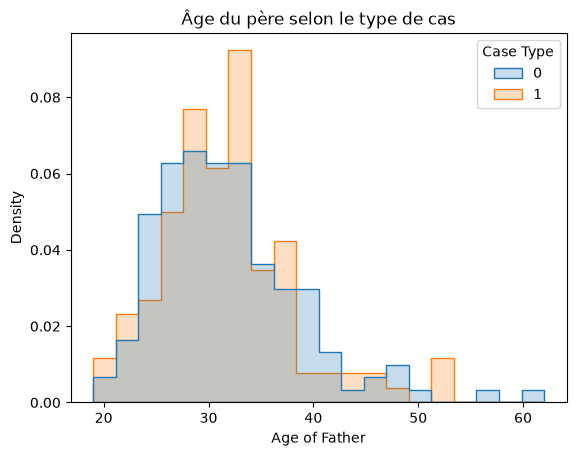

In [315]:
sns.histplot(data=df, x="Age of Father", hue="Case Type", bins=20,
             stat="density", common_norm=False, element="step")
plt.title("Âge du père selon le type de cas")
plt.show()

### Analyse et conclusion
D'après la distribution Age of Father, on voit que la majorité des pères ont un âge compris entre 22 ans et 48 ans pour tout de type de cas confondu. Et on ne peut pas conclure que Age of Father varie selon les cas.

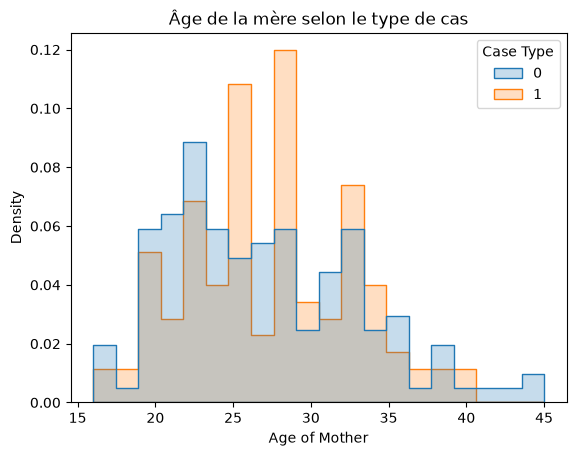

In [316]:
sns.histplot(data=df, x="Age of Mother", hue="Case Type", bins=20,
             stat="density", common_norm=False, element="step")
plt.title("Âge de la mère selon le type de cas")
plt.show()

### Analyse et Conclusion
Même conclusion que l'âge du père

## Digramme de corrélation

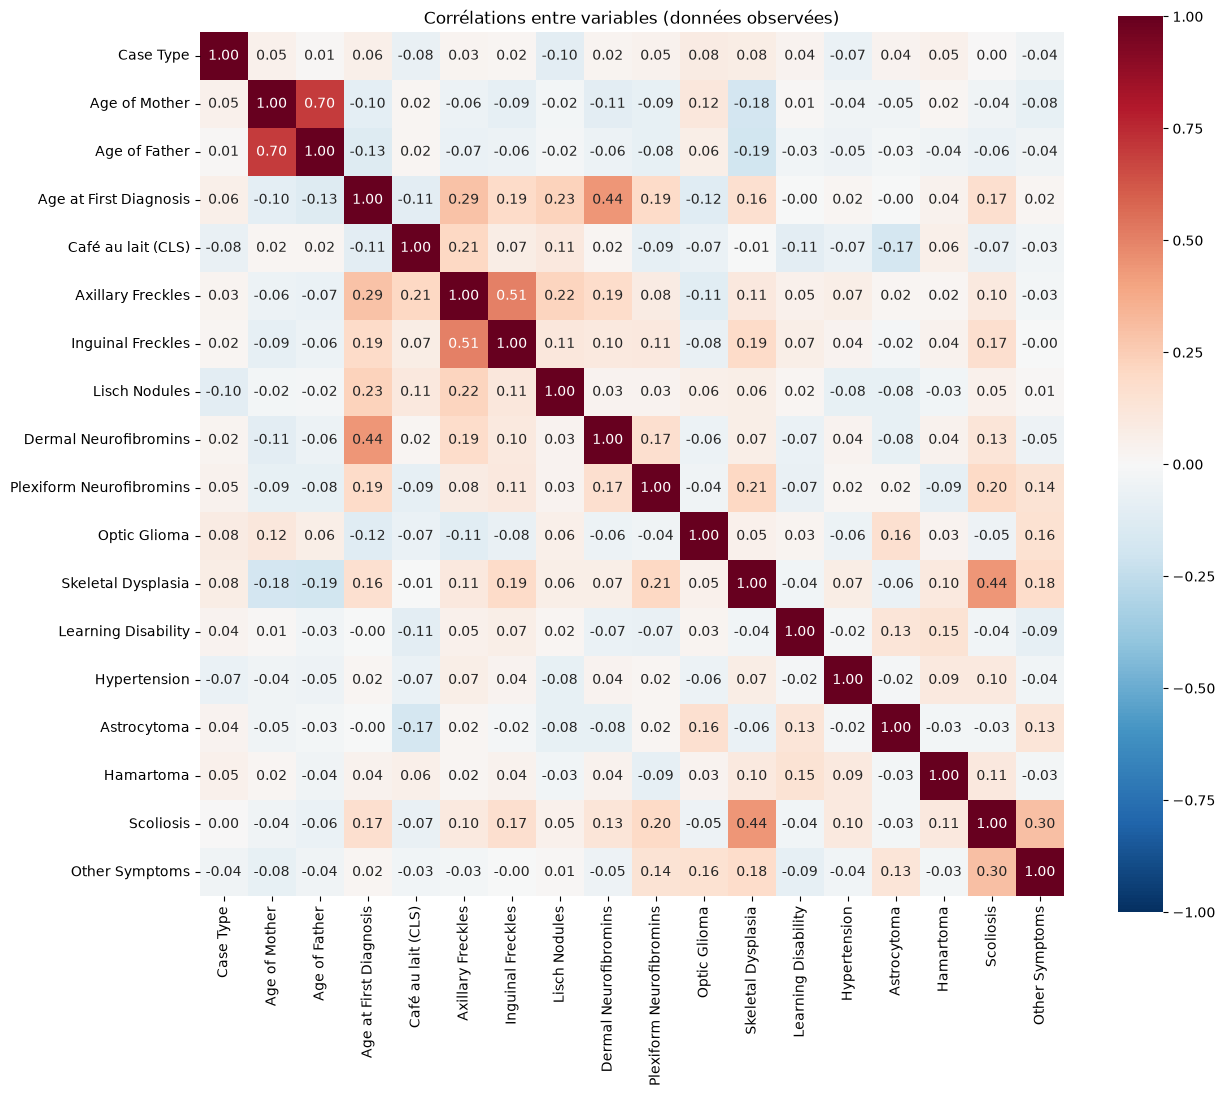

                          Case Type  Age of Mother  Age of Father  \
Case Type                       296            261            262   
Age of Mother                   261            261            258   
Age of Father                   262            258            262   
Age at First Diagnosis          292            261            262   
Café au lait (CLS)              296            261            262   
Axillary Freckles               296            261            262   
Inguinal Freckles               296            261            262   
Lisch Nodules                   296            261            262   
Dermal Neurofibromins           296            261            262   
Plexiform Neurofibromins        296            261            262   
Optic Glioma                    296            261            262   
Skeletal Dysplasia              296            261            262   
Learning Disability             296            261            262   
Hypertension                    29

In [317]:
data =  df.drop(columns=["Tumour Case", "Unnamed: 0"])
corr = data.corr(method="spearman")

plt.figure(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Corrélations entre variables (données observées)")
plt.tight_layout()
plt.show()

obs = data.notna().astype(int)
n_paires = obs.T @ obs
print(n_paires)
print(len(df))


Commentaire du diagramme de corrélation (Spearman)

Cible. La première ligne est la plus importante : aucune variable n’est corrélée au type de cas (|ρ| ≤ 0,10, maximum pour les nodules de Lisch). Les variables explicatives ne portent pas d’information linéaire ou monotone sur la cible.

Âges des parents, Âge de la mère et âge du père : ρ = 0,70. Attendu, les conjoints ont des âges proches.

L’âge au diagnostic est lié à plusieurs symptômes : neurofibromes dermiques (0,44), taches de rousseur axillaires (0,29), nodules de Lisch (0,23), inguinales et plexiformes (0,19). Ces signes apparaissent avec l’âge ; un diagnostic tardif est posé sur un patient plus âgé, qui les présente plus souvent. L’âge au diagnostic joue ici le rôle de l’âge du patient, absent du jeu de données.

Symptômes qui vont ensemble. Taches axillaires et inguinales (0,51) : deux localisations du même signe. Dysplasie squelettique et scoliose (0,44), scoliose et autres symptômes (0,30) : une composante osseuse commune.

Le reste est inférieur à 0,22 en valeur absolue, donc faible ou non significatif après correction pour tests multiples. Les quelques valeurs négatives (âges des parents et dysplasie squelettique, −0,18 et −0,19) sont à la limite et sans interprétation évidente.

Conséquence pour la modélisation : pas de prédicteur isolé de la cible

Étude de chaque variable par rapport à la cible

In [318]:
# Étude bivariée : variables explicatives vs cible (Case Type)
cols_age = ["Age of Mother", "Age of Father", "Age at First Diagnosis"]
cols_bin = [
    col for col in df.columns
    if col not in cols_age + ["Case Type", "Unnamed: 0"]
]
cible = df["Case Type"]

resultats_cible = []

# Variables continues : test de Mann-Whitney
for col in cols_age:
    groupe_0 = df.loc[cible == 0, col].dropna()
    groupe_1 = df.loc[cible == 1, col].dropna()

    _, p_val = mannwhitneyu(groupe_0, groupe_1, alternative="two-sided")
    resultats_cible.append({
        "Variable": col,
        "Type": "Continu (Âge)",
        "Médiane (Sporadique=0)": groupe_0.median(),
        "Médiane (Familial=1)": groupe_1.median(),
        "p-value": p_val,
    })

# Variables binaires : test Fisher
for col in cols_bin:
    contingency_table = pd.crosstab(df[col], cible)
    p_val_2 = fisher_exact(contingency_table).pvalue

    prop_0 = df.loc[cible == 0, col].mean() * 100
    prop_1 = df.loc[cible == 1, col].mean() * 100
    resultats_cible.append({
        "Variable": col,
        "Type": "Binaire",
        "Prévalence % (Sporadique=0)": f"{prop_0:.1f}%",
        "Prévalence % (Familial=1)": f"{prop_1:.1f}%",
        "p-value": p_val_2,
    })

df_cible = pd.DataFrame(resultats_cible)
display(df_cible.sort_values(by="p-value"))

,Variable,Type,Médiane (Sporadique=0),Médiane (Familial=1),p-value,Prévalence % (Sporadique=0),Prévalence % (Familial=1)
7,Lisch Nodules,Binaire,NaN,NaN,0.091182,32.3%,23.0%
10,Optic Glioma,Binaire,NaN,NaN,0.153981,13.0%,19.3%
11,Skeletal Dysplasia,Binaire,NaN,NaN,0.233142,16.1%,22.2%
4,Café au lait (CLS),Binaire,NaN,NaN,0.245058,95.0%,91.1%
2,Age at First Diagnosis,Continu (Âge),8.0,9.0,0.295250,NaN,NaN
3,Tumour Case,Binaire,NaN,NaN,0.363870,25.5%,30.4%
13,Hypertension,Binaire,NaN,NaN,0.380479,2.5%,0.7%
0,Age of Mother,Continu (Âge),26.5,28.0,0.385472,NaN,NaN
15,Hamartoma,Binaire,NaN,NaN,0.419130,3.7%,5.9%
17,Other Symptoms,Binaire,NaN,NaN,0.463056,36.0%,31.9%


L'analyse bivariée exploratoire (via les tests de Mann-Whitney pour les variables continues et du fisher pour les variables binaires) montre qu'aucune variable prise isolément ne discrimine de façon statistiquement significative ($p \le 0,05$) le type de cas (sporadique vs familial). Les symptômes majeurs comme les taches café-au-lait affichent des prévalences très élevées et similaires dans les deux groupes.

In [319]:
# Copie de travail pour l'analyse des valeurs manquantes
df_missing = df[["Case Type", "Age of Mother", "Age of Father", "Age at First Diagnosis"]].copy()

# Création d'indicateurs binaires d'absence (1 = manquant, 0 = présent)
df_missing["Mother_Missing"] = df_missing["Age of Mother"].isna().astype(int)
df_missing["Father_Missing"] = df_missing["Age of Father"].isna().astype(int)
df_missing["Diag_Missing"] = df_missing["Age at First Diagnosis"].isna().astype(int)

# Test de Fisher sur un indicateur d'absence (binaire) croisé avec la cible (binaire)
def run_fisher_test(col_name):
    contingency_table = pd.crosstab(df_missing[col_name], df_missing["Case Type"])
    # fisher_exact attend une table de contingence 2x2
    res = fisher_exact(contingency_table)
    return contingency_table, res.pvalue

# Exécution pour les trois indicateurs d'absence
for col in ["Mother_Missing", "Father_Missing", "Diag_Missing"]:
    table, p_val = run_fisher_test(col)
    print(f"\n--- Test de Fisher pour : {col} ---")
    display(table)
    print(f"p-value = {p_val:.4f}")
    if p_val > 0.05:
        print("-> Aucun lien significatif n'a été détecté entre l'absence de l'âge et la cible (p > 0.05).")
    else:
        print("-> Lien statistiquement significatif détecté (p <= 0.05).")


--- Test de Fisher pour : Mother_Missing ---


Case Type,0,1
Mother_Missing,,
0,140,121
1,21,14


p-value = 0.5884
-> Aucun lien significatif n'a été détecté entre l'absence de l'âge et la cible (p > 0.05).

--- Test de Fisher pour : Father_Missing ---


Case Type,0,1
Father_Missing,,
0,141,121
1,20,14


p-value = 0.7149
-> Aucun lien significatif n'a été détecté entre l'absence de l'âge et la cible (p > 0.05).

--- Test de Fisher pour : Diag_Missing ---


Case Type,0,1
Diag_Missing,,
0,159,133
1,2,2


p-value = 1.0000
-> Aucun lien significatif n'a été détecté entre l'absence de l'âge et la cible (p > 0.05).


Séparation Train / Test et Configuration du Pipeline

In [320]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Case Type est déjà codée 0/1; on garde ces valeurs sans supposer leur signification.
y = df["Case Type"].astype("int64")
X = df.drop(columns=["Case Type", "Unnamed: 0"])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Définition du pipeline de prétraitement
prepro = ColumnTransformer([
    ("ages", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), cols_age),
    ("bin", "passthrough", cols_bin),
])

print("Répartition de la cible (codes 0/1) :")
display(y.value_counts().sort_index().rename("effectif").to_frame())

Répartition de la cible (codes 0/1) :


,effectif
Case Type,
0,161
1,135


### 1. Pourquoi imputer plutôt que supprimer la colonne ?

Supprimer une colonne représente une perte d'information définitive. L'imputation est peu risquée ici car les valeurs manquantes sont rares (11,8 % pour la mère, 11,5 % pour le père et 1,4 % pour le diagnostic).

---

### 2. Pourquoi ne pas supprimer les lignes incomplètes ?
Supprimer toutes les lignes incomplètes ferait perdre entre 38 , ce qui est considérable sur un échantillon déjà restreint.
Les tests de Fisher ne détectent pas de lien entre l’absence des âges et la cible (p = 0,59 ; 0,71 ; 1,00). Rien n’indique donc que la suppression des lignes incomplètes biaiserait l’échantillon, mais un lien faible ne peut pas être exclu avec cet effectif.

---

### 4. Faut-il utiliser la moyenne ou la médiane ?

* La médaine est privilégiée pour les trois âges, car elle est robuste aux valeurs extrêmes et aux asymétries (par exemple, l'âge au diagnostic est souvent très asymétrique avec beaucoup d'enfants et quelques adultes). par contre y'a pas une gande difference entre la médianne et la moyenne pour l'age des parents
---

### 5. Quel est l'intérêt de l'âge du père et comment trancher son utilité ?

 L'étude de Sharafi et al. (2018) conclut qu'il n'y a pas d'effet démontré de l'âge des parents sur la *gravité* clinique de la NF1. Cependant, notre projet cible la distinction entre cas sporadique et familial (l'hypothèse étant qu'une mutation nouvelle est plus fréquente chez un père plus âgé). On teste l'effet de l'âge du père via un boxplot et un test de Mann-Whitney, mais la décision finale de garder ou non la variable se prend objectivement grâce à une comparaison de modèles en validation croisée imbriquée (avec vs sans l'âge du père).

---

### 6. Comment expliquer l'écart de cohorte entre la page UCI (331 cas) et nos données (296 patients) ?

Bien que la notice descriptive initiale du dépôt UCI mentionne de manière erronée une cohorte théorique de 309 cas, l'analyse du fichier source brut mis à disposition recense effectivement **296 patients exploitables** (161 de classe 0 et 135 de classe 1), sans valeur manquante sur la variable cible.inspecter le fichier brut d'origine avec un tableau croisé pour vérifier si le filtre a par inadvertance retiré de vrais patients portant un type de cas._